# 📊 Exploratory Data Analysis (EDA) — Darija Sentiment Classifier

This notebook explores the combined Moroccan Darija sentiment dataset (`data/processed/combined.parquet`).
Key focus areas:
1. **Source distribution**: MYC, MAC, MSDA
2. **Class balance**: Overall and per-script (Arabic, Arabizi, Mixed)
3. **Script distribution**: Character rules and Arabizi digit heuristics
4. **Text length distributions**: Character and token lengths
5. **Top n-grams**: Most frequent words per sentiment class and script
6. **Representative examples**: Sample comments across all categories


In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
import re

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'sans-serif']
plt.rcParams['figure.dpi'] = 150

RESULTS_DIR = Path('../results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DATA_PATH = Path('../data/processed/combined.parquet')


In [2]:
df = pd.read_parquet(DATA_PATH)
print(f"Total rows loaded: {len(df):,}")
print(f"Columns: {list(df.columns)}")
df.head(5)


Total rows loaded: 36,201
Columns: ['text', 'text_raw', 'label', 'script', 'source', 'original_label']


,text,text_raw,label,script,source,original_label
0,انسان عبارة عن دواء للإكتئاب❤🎤,انسان عبارة عن دواء للإكتئاب❤🎤,positive,arabic,MYC,1
1,نحبك يا فنان وااحساان❤,نحبك يا فنان وااااااحسااااااااان❤,positive,arabic,MYC,1
2,Stream zuin😂 Thank you ilyas ❤️🫶,Stream zuin😂 Thank you ilyas ❤️🫶,positive,arabizi,MYC,1
3,وحق الرب الى دوا د الاكتئاب الأسطورة❤️❤️❤️❤️😂,وحق الرب الى دوا د الاكتئاب الأسطورة❤️❤️❤️❤️😂,positive,arabic,MYC,1
4,اسطورة بكل ما تحمل الكلمة من معنى ❤,اسطورة بكل ما تحمل الكلمة من معنى ❤,positive,arabic,MYC,1


## 1. Rows per Data Source

source
MYC     18699
MAC     12337
MSDA     5165
Name: count, dtype: int64


/var/folders/tk/k3m48g193rq48ymzq86k7thh0000gn/T/ipykernel_58608/3084349631.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=source_counts.index, y=source_counts.values, palette='Blues_r', ax=ax)


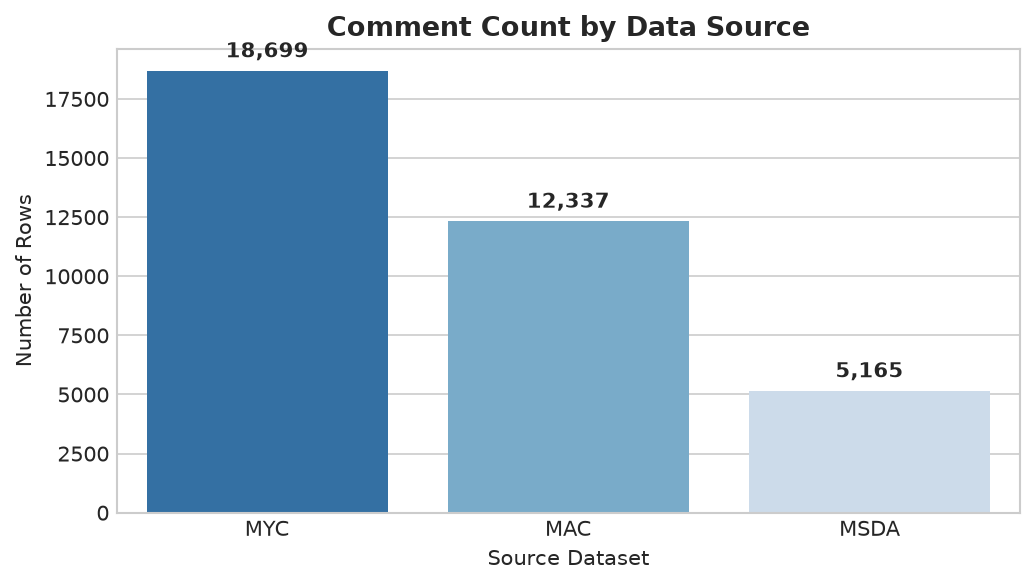

In [3]:
source_counts = df['source'].value_counts()
print(source_counts)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=source_counts.index, y=source_counts.values, palette='Blues_r', ax=ax)
ax.set_title('Comment Count by Data Source', fontsize=13, fontweight='bold')
ax.set_xlabel('Source Dataset')
ax.set_ylabel('Number of Rows')
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 4), textcoords='offset points', fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'eda_sources.png', dpi=150)
plt.show()


## 2. Script Distribution (Arabic vs Arabizi vs Mixed)

script
arabic     30394
arabizi     4752
mixed       1055
Name: count, dtype: int64

Percentages:
script
arabic     83.96%
arabizi    13.13%
mixed       2.91%
Name: count, dtype: str


/var/folders/tk/k3m48g193rq48ymzq86k7thh0000gn/T/ipykernel_58608/1473085935.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=script_counts.index, y=script_counts.values, palette=colors, ax=ax2)


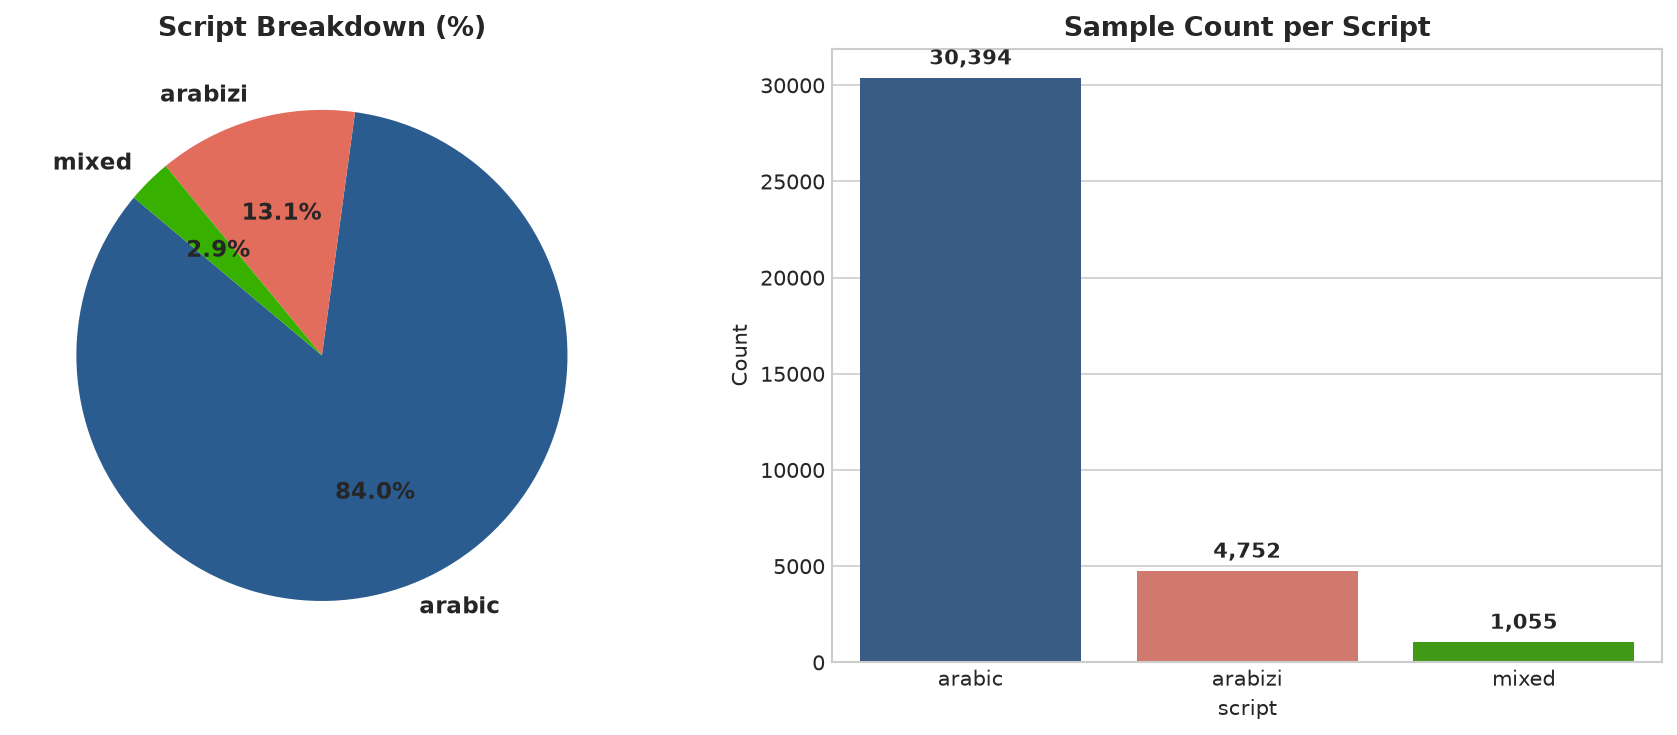

In [4]:
script_counts = df['script'].value_counts()
print(script_counts)
print("\nPercentages:")
print((script_counts / len(df) * 100).round(2).astype(str) + '%')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
colors = ['#2b5c8f', '#e26d5c', '#38b000']

# Pie chart
ax1.pie(script_counts.values, labels=script_counts.index, autopct='%1.1f%%',
        startangle=140, colors=colors, textprops={'fontsize': 11, 'fontweight': 'bold'})
ax1.set_title('Script Breakdown (%)', fontsize=13, fontweight='bold')

# Bar chart
sns.barplot(x=script_counts.index, y=script_counts.values, palette=colors, ax=ax2)
ax2.set_title('Sample Count per Script', fontsize=13, fontweight='bold')
ax2.set_ylabel('Count')
for p in ax2.patches:
    ax2.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 4), textcoords='offset points', fontweight='bold')

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'eda_scripts.png', dpi=150)
plt.show()


## 3. Class Balance Overall and Per Script

Overall label distribution:
label
positive    17541
negative    13497
neutral      5163
Name: count, dtype: int64

Cross-tabulation (Label x Script):
script    arabic  arabizi  mixed    All
label                                  
negative   11669     1418    410  13497
neutral     5037       82     44   5163
positive   13688     3252    601  17541
All        30394     4752   1055  36201


/var/folders/tk/k3m48g193rq48ymzq86k7thh0000gn/T/ipykernel_58608/440448623.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=label_counts.index, y=label_counts.values, palette=['#40916c', '#d90429', '#adb5bd'], ax=ax1)


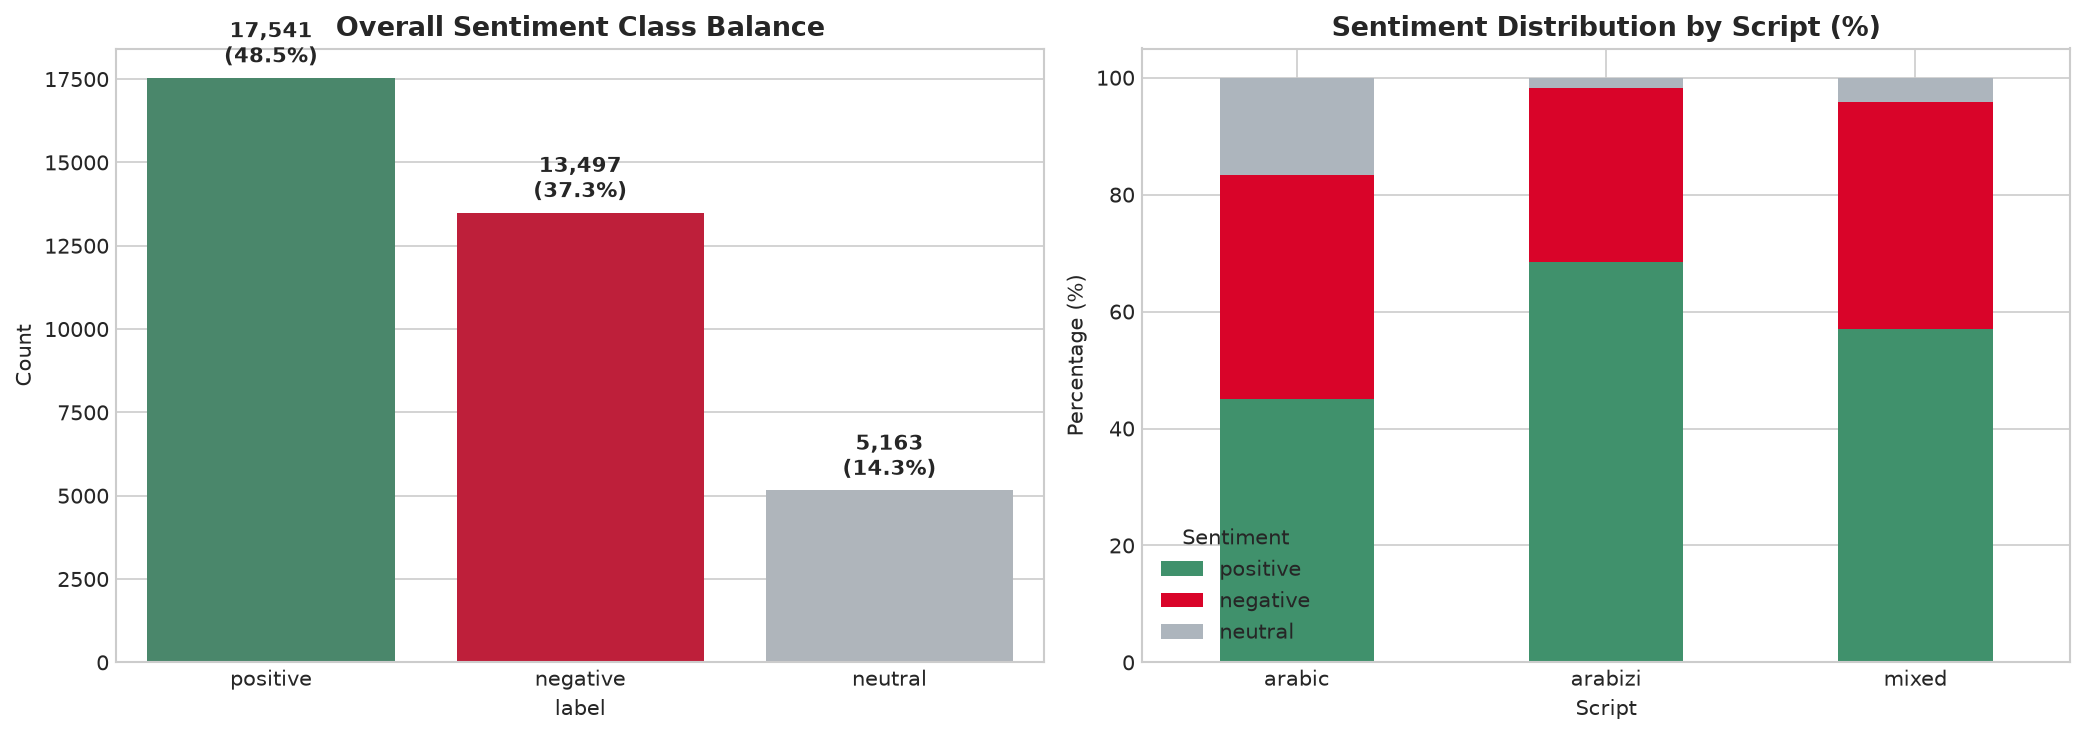

In [5]:
label_counts = df['label'].value_counts()
print("Overall label distribution:")
print(label_counts)

crosstab = pd.crosstab(df['label'], df['script'], margins=True)
print("\nCross-tabulation (Label x Script):")
print(crosstab)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Overall label barplot
sns.barplot(x=label_counts.index, y=label_counts.values, palette=['#40916c', '#d90429', '#adb5bd'], ax=ax1)
ax1.set_title('Overall Sentiment Class Balance', fontsize=13, fontweight='bold')
ax1.set_ylabel('Count')
for p in ax1.patches:
    pct = p.get_height() / len(df) * 100
    ax1.annotate(f"{int(p.get_height()):,}\n({pct:.1f}%)", 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 4), textcoords='offset points', fontweight='bold')

# Per-script label distribution
ct_pct = pd.crosstab(df['script'], df['label'], normalize='index') * 100
ct_pct[['positive', 'negative', 'neutral']].plot(kind='bar', stacked=True, 
                                                 color=['#40916c', '#d90429', '#adb5bd'], ax=ax2)
ax2.set_title('Sentiment Distribution by Script (%)', fontsize=13, fontweight='bold')
ax2.set_ylabel('Percentage (%)')
ax2.set_xlabel('Script')
ax2.legend(title='Sentiment')
plt.setp(ax2.get_xticklabels(), rotation=0)

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'eda_class_balance.png', dpi=150)
plt.show()


## 4. Text Length Distributions

Character length summary:
           count        mean         std  min   50%     max
script                                                     
arabic   30394.0   60.383924   65.455676  1.0  41.0  1743.0
arabizi   4752.0   42.755261   47.882456  1.0  29.0  1218.0
mixed     1055.0  129.717536  171.118665  6.0  88.0  2535.0


/var/folders/tk/k3m48g193rq48ymzq86k7thh0000gn/T/ipykernel_58608/2567672233.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df[df['char_length'] <= p99], x='script', y='char_length', palette='Set2', ax=ax1)


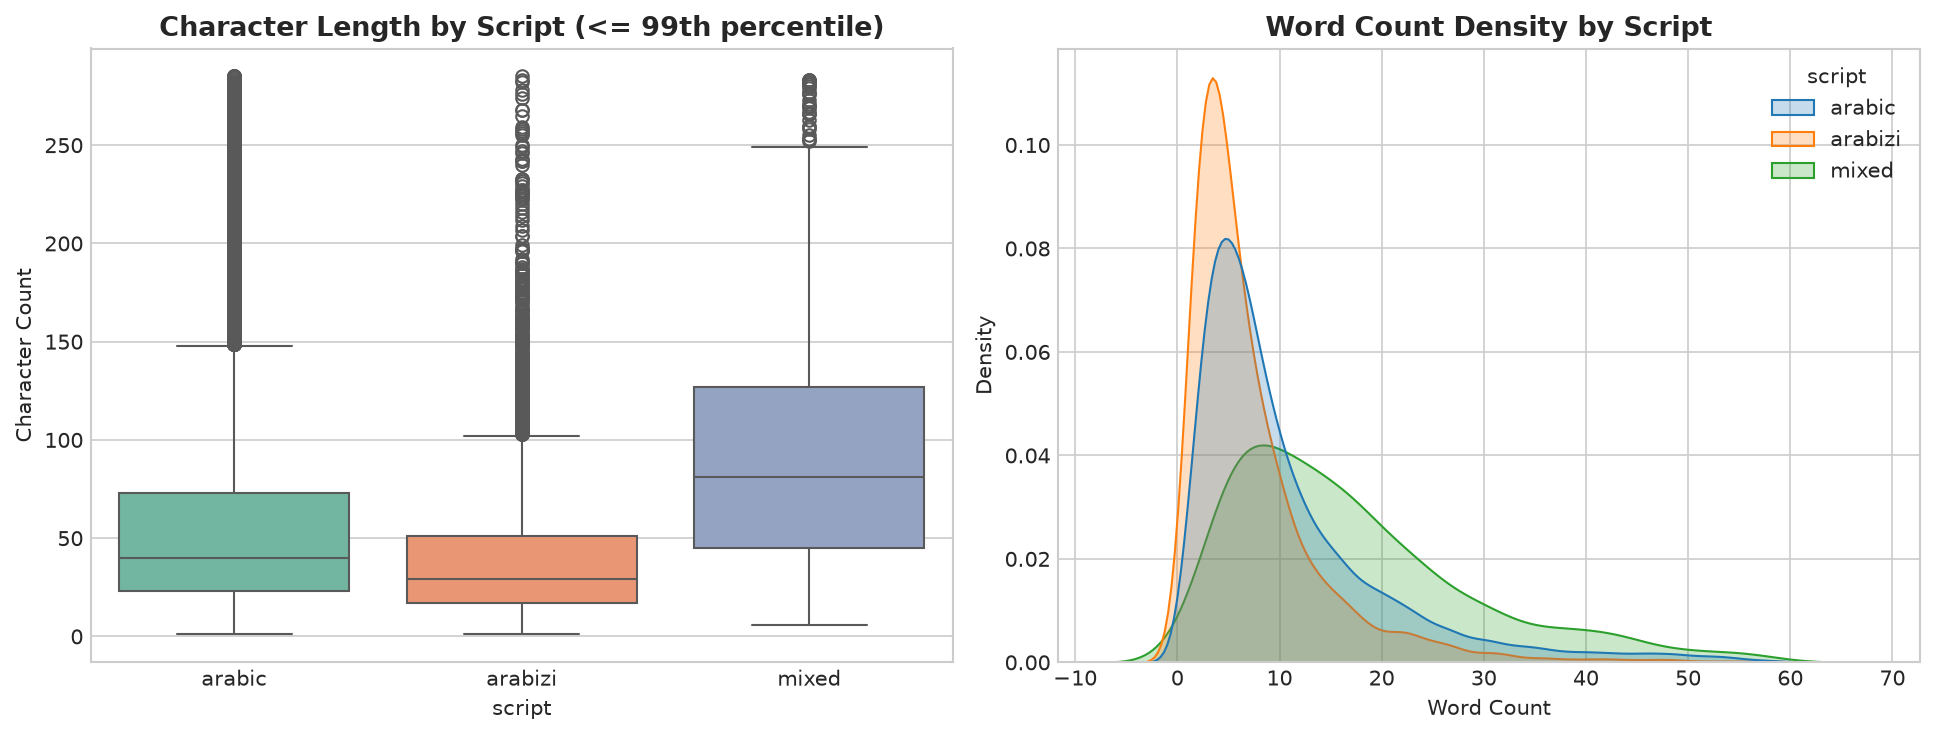

In [6]:
df['char_length'] = df['text'].str.len()
df['word_count'] = df['text'].str.split().str.len()

print("Character length summary:")
print(df.groupby('script')['char_length'].describe()[['count', 'mean', 'std', 'min', '50%', 'max']])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

p99 = df['char_length'].quantile(0.99)
sns.boxplot(data=df[df['char_length'] <= p99], x='script', y='char_length', palette='Set2', ax=ax1)
ax1.set_title('Character Length by Script (<= 99th percentile)', fontsize=13, fontweight='bold')
ax1.set_ylabel('Character Count')

sns.kdeplot(data=df[df['word_count'] <= 60], x='word_count', hue='script', common_norm=False, ax=ax2, fill=True)
ax2.set_title('Word Count Density by Script', fontsize=13, fontweight='bold')
ax2.set_xlabel('Word Count')
ax2.set_ylabel('Density')

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'eda_text_lengths.png', dpi=150)
plt.show()


## 5. Top Words per Class and Script

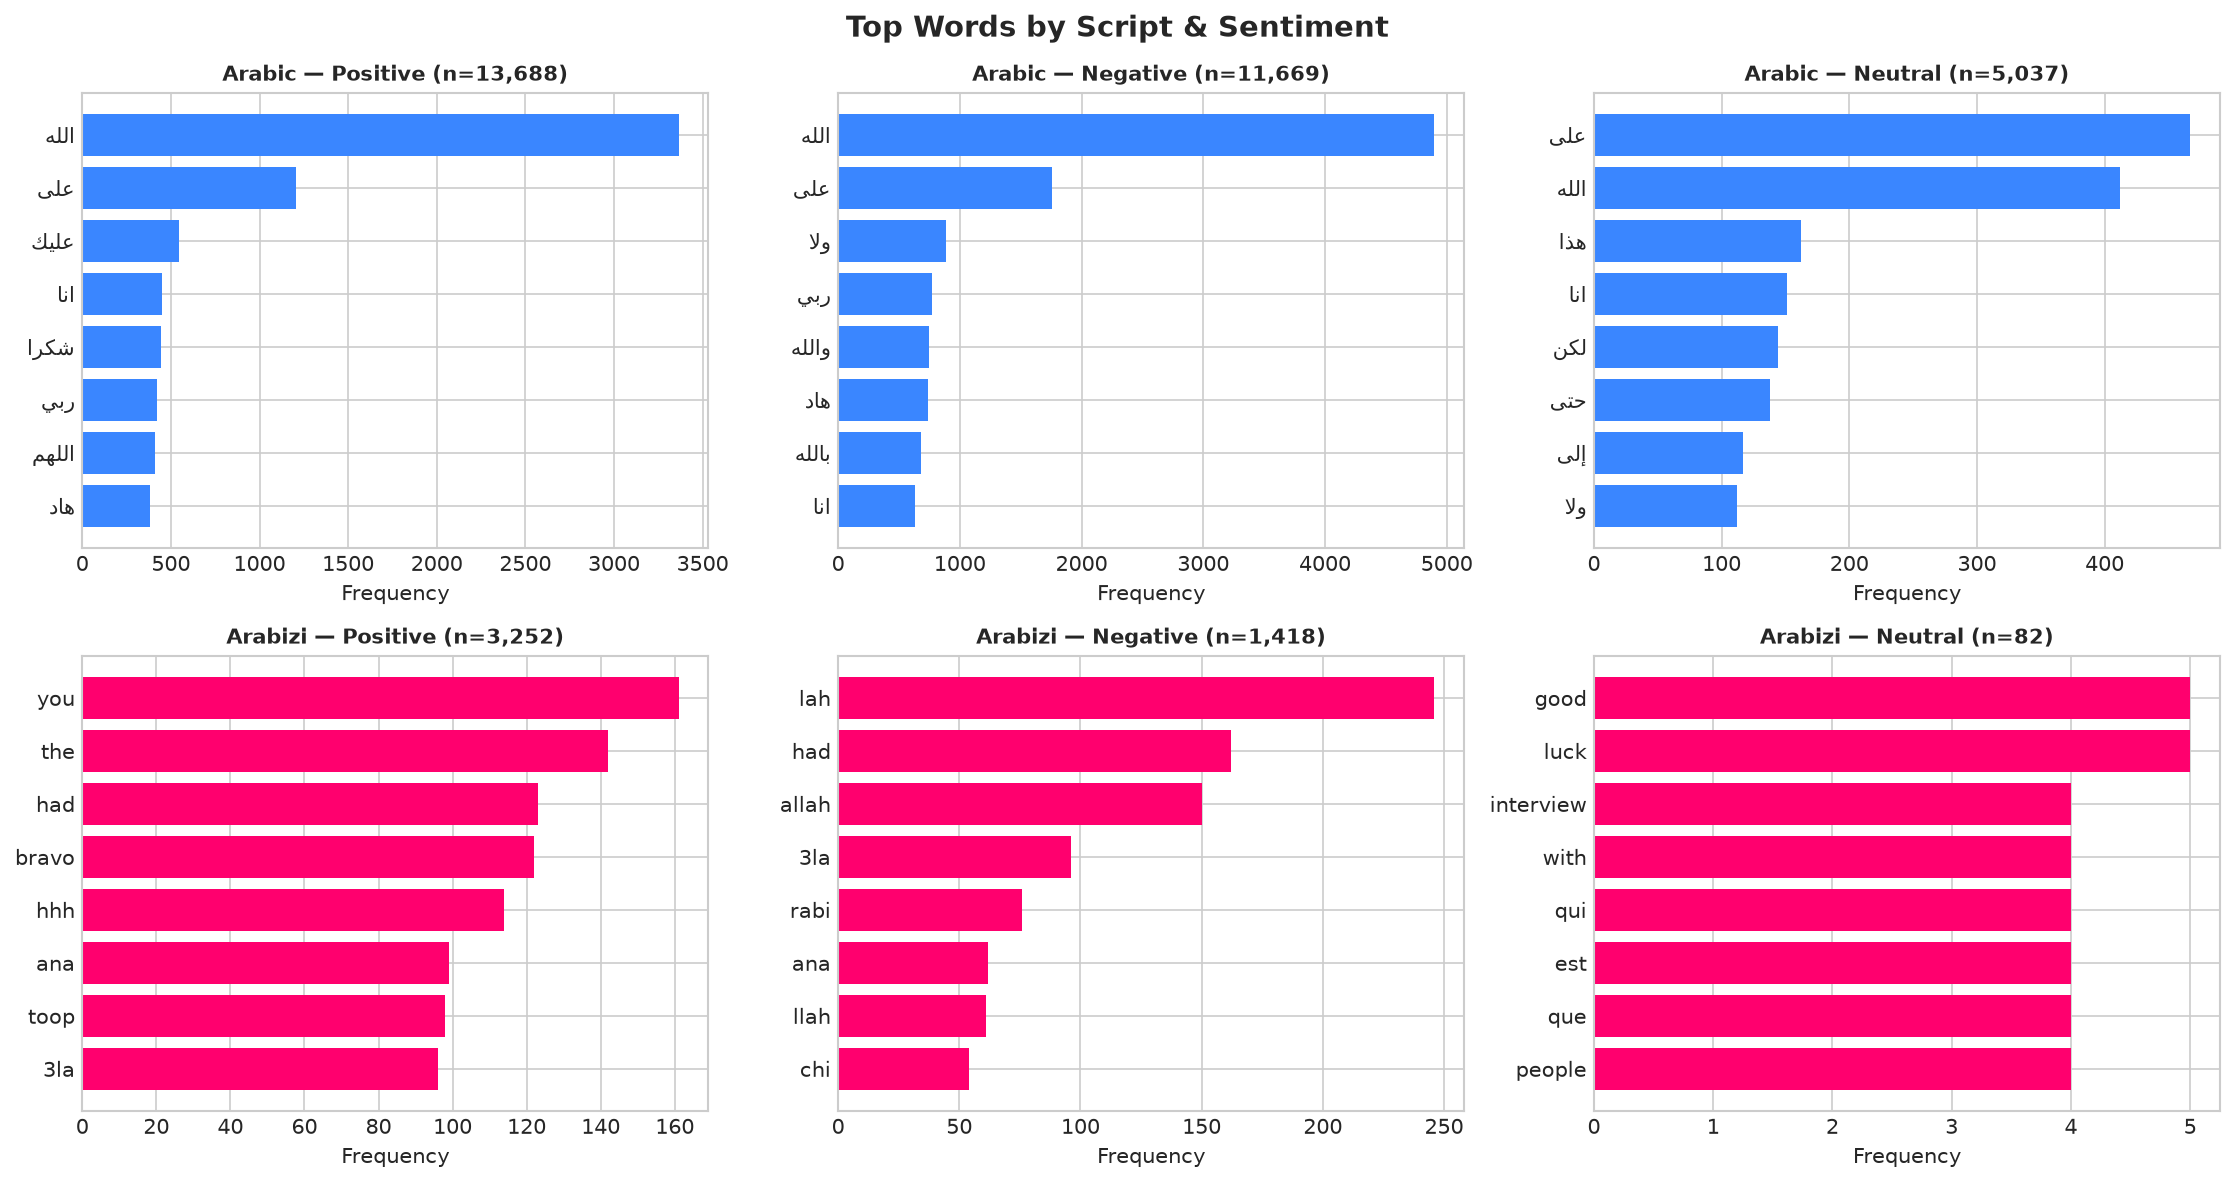

In [7]:
def get_top_tokens(texts, n=10):
    words = []
    for t in texts:
        tokens = re.findall(r'\w+', str(t).lower())
        words.extend([w for w in tokens if len(w) > 2])
    return Counter(words).most_common(n)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle('Top Words by Script & Sentiment', fontsize=14, fontweight='bold')

for s_idx, script in enumerate(['arabic', 'arabizi']):
    for l_idx, label in enumerate(['positive', 'negative', 'neutral']):
        sub = df[(df['script'] == script) & (df['label'] == label)]
        top = get_top_tokens(sub['text'], n=8)
        ax = axes[s_idx, l_idx]
        if top:
            words, counts = zip(*top)
            ax.barh(range(len(words)), counts, color='#3a86ff' if script=='arabic' else '#ff006e')
            ax.set_yticks(range(len(words)))
            ax.set_yticklabels(words)
            ax.invert_yaxis()
        ax.set_title(f"{script.title()} — {label.title()} (n={len(sub):,})", fontsize=10, fontweight='bold')
        ax.set_xlabel('Frequency')

plt.tight_layout()
plt.savefig(RESULTS_DIR / 'eda_top_words.png', dpi=150)
plt.show()


## 6. Sample Texts per Script and Sentiment

In [8]:
for script in ['arabic', 'arabizi', 'mixed']:
    print(f"=== SCRIPT: {script.upper()} ===")
    for label in ['positive', 'negative', 'neutral']:
        samples = df[(df['script'] == script) & (df['label'] == label)]['text'].head(3).tolist()
        print(f"\n  [{label.upper()}]:")
        for i, s in enumerate(samples, 1):
            print(f"    {i}. {s}")
    print("\n" + "-"*60 + "\n")


=== SCRIPT: ARABIC ===

  [POSITIVE]:
    1. انسان عبارة عن دواء للإكتئاب❤🎤
    2. نحبك يا فنان وااحساان❤
    3. وحق الرب الى دوا د الاكتئاب الأسطورة❤️❤️❤️❤️😂

  [NEGATIVE]:
    1. حسبنا الله ونعم الوكيل الله ينتقم منهم المجرمين والضالمين
    2. نهار على نهار كنزيد نتأكد ان المغرب ما فيهش الفقراء هه واش وحدة تشوفها فالزنقة تقدر تصدق عليها بحال هاديك لي لابسة الاسمال، و فلخر تلقاها عندها ستة د لمليون تحت منها و لا داك البناي لي لقاو عندو سبعة و عشرين مليون جامعها و تعرفات القضية غي فاش خرج للإعلام حيت مشات ليه من البنكة و زيد و زيد..بلا منبقاو فداك التمثيل، كلشي تفرش: لمغربي لمكرد را عندو شي ملينات بالضرورة هه. من الان فصاعدا مبقيتش نتصدق على البشر، درهم شاطت عليا نشريها فرماجة لقط دايزة فيه
    3. اللي كيتحمل المسؤلية هو مدير المؤسسة لأنه هو المسؤول الأول والأخير في المؤسسة هو اللي خاصو يتخذ قرار في حق هذه الموظفة بالمتابعة وإرجاع الأموال إلى أصحابها..

  [NEUTRAL]:
    1. : ❤
    2. لا يا حبيبي محد له حق على احد الا اذا اخترت الاشخاص الي بيدخلون كل شخص ملك لنفسه
    3. قريباً 😂

-----